In [1]:
# IMPORT LIBRARY
try:
    from imblearn.combine import SMOTETomek
except ImportError:
    !pip install -q imbalanced-learn
    from imblearn.combine import SMOTETomek

import os
import random
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore")

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Environment siap! Perangkat komputasi yang digunakan: {DEVICE}")

Environment siap! Perangkat komputasi yang digunakan: cpu


In [2]:
FILE_PATH = "/content/dataset_klasifikasi_hujan_pekanbaru.csv"

def muat_dan_bersihkan_data(path):

    with open(path, "r", encoding="utf-8", errors="replace") as f:
        baris_pertama = f.readline()
    sep = ";" if baris_pertama.count(";") > baris_pertama.count(",") else ","

    df = pd.read_csv(path, sep=sep, dtype=str)
    jumlah_baris_awal = len(df)

    # Konversi kolom 'time' menjadi format waktu standar (datetime64)
    df["time"] = pd.to_datetime(df["time"], dayfirst=(sep == ";"))

    # Hapus duplikasi stempel waktu (jika ada) dan urutkan kronologis dari awal ke akhir
    df = (
        df.drop_duplicates(subset=["time"])
          .sort_values("time")
          .reset_index(drop=True)
    )

    kolom_fitur = [c for c in df.columns if c not in ["time", "target_hujan_next_1h"]]
    for col in kolom_fitur:
        df[col] = (
            df[col]
            .astype(str)
            .str.strip()
            .str.replace(",", ".", regex=False)
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Konversi kolom target klasifikasi menjadi bilangan bulat biner (0 = Tidak Hujan, 1 = Hujan)
    df["target_hujan_next_1h"] = pd.to_numeric(df["target_hujan_next_1h"], errors="coerce").astype(int)

    df["hour_sin"] = np.sin(2 * np.pi * df["time"].dt.hour / 24.0)
    df["hour_cos"] = np.cos(2 * np.pi * df["time"].dt.hour / 24.0)
    df["wind_direction_sin"] = df["wind_direction_sin"].clip(-1.0, 1.0)
    df["wind_direction_cos"] = df["wind_direction_cos"].clip(-1.0, 1.0)

    df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
    jumlah_baris_akhir = len(df)

    return df, jumlah_baris_awal, jumlah_baris_akhir

df, baris_awal, baris_akhir = muat_dan_bersihkan_data(FILE_PATH)

print("TAHAP 1: RINGKASAN DATASET SETELAH PEMBERSIHAN (PREPROCESSING AWAL)")
print(f"Jumlah observasi awal    : {baris_awal} baris")
print(f"Jumlah observasi bersih  : {baris_akhir} baris (Terbuang: {baris_awal - baris_akhir} baris / 100% utuh)")
print(f"Dimensi tabel awal       : {df.shape[0]} baris x {df.shape[1]} kolom (19 fitur cuaca + time + target)")
print(f"Periode waktu pengamatan : {df['time'].min()} s/d {df['time'].max()}")
print(f"Total missing values     : {df.isnull().sum().sum()}")

TAHAP 1: RINGKASAN DATASET SETELAH PEMBERSIHAN (PREPROCESSING AWAL)
Jumlah observasi awal    : 6573 baris
Jumlah observasi bersih  : 6573 baris (Terbuang: 0 baris / 100% utuh)
Dimensi tabel awal       : 6573 baris x 21 kolom (19 fitur cuaca + time + target)
Periode waktu pengamatan : 2026-01-18 02:00:00 s/d 2026-10-18 22:00:00
Total missing values     : 0


TAHAP 2: EXPLORATORY DATA ANALYSIS (EDA)
Kelas 0 (Tidak Hujan) : 4490 jam (68.31%)
Kelas 1 (Hujan)       : 2083 jam (31.69%)
Imbalance Ratio (IR)  : 2.16 : 1

[Temuan EDA 1] Kejadian hujan mendadak dari kondisi kering: 646 dari 2083 kejadian (31.01%)

[Temuan EDA 2] 5 Jam Pengamatan Paling Rawan Hujan 1 Jam ke Depan (WIB):
     total_observasi  jumlah_hujan  peluang_hujan_persen
jam                                                     
11               274           171                 62.41
12               274           153                 55.84
10               274           148                 54.01
13               274           129                 47.08
16               274           108                 39.42

[Temuan EDA 2] 5 Jam Pengamatan Paling Aman / Kering (WIB):
     total_observasi  jumlah_hujan  peluang_hujan_persen
jam                                                     
7                274            33                 12.04
19               274            41          

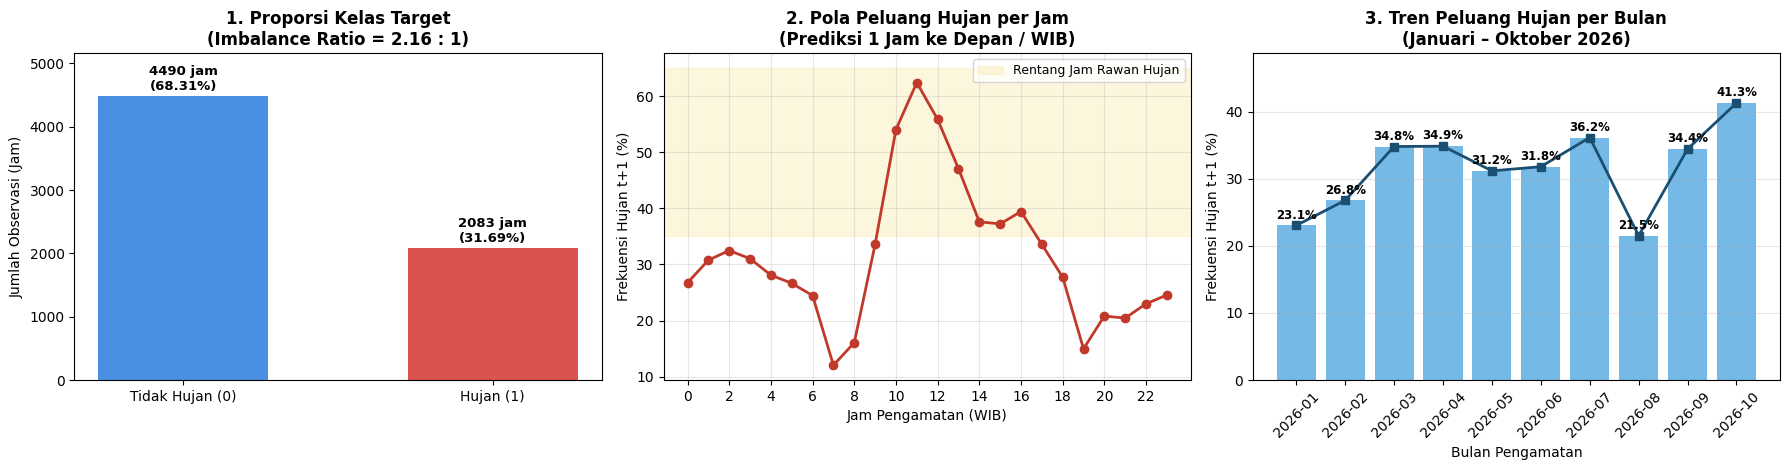

In [3]:
print("TAHAP 2: EXPLORATORY DATA ANALYSIS (EDA)")

# 1. Menghitung proporsi kelas target dan Imbalance Ratio (IR = mayoritas / minoritas)
vc = df["target_hujan_next_1h"].value_counts().sort_index()
vcp = df["target_hujan_next_1h"].value_counts(normalize=True).sort_index() * 100
ir = vc[0] / vc[1]

print(f"Kelas 0 (Tidak Hujan) : {vc[0]} jam ({vcp[0]:.2f}%)")
print(f"Kelas 1 (Hujan)       : {vc[1]} jam ({vcp[1]:.2f}%)")
print(f"Imbalance Ratio (IR)  : {ir:.2f} : 1")

# 2. Menghitung frekuensi hujan mendadak (saat jam sekarang kering, 1 jam lagi hujan)
kering_sekarang = df[df["rain_prev_1h"] < 0.05]
hujan_mendadak = kering_sekarang[kering_sekarang["target_hujan_next_1h"] == 1]
persen_mendadak = (len(hujan_mendadak) / vc[1]) * 100
print(f"\n[Temuan EDA 1] Kejadian hujan mendadak dari kondisi kering: "
      f"{len(hujan_mendadak)} dari {vc[1]} kejadian ({persen_mendadak:.2f}%)")

# 3. Menghitung peluang hujan 1 jam ke depan berdasarkan jam pengamatan (00.00-23.00 WIB)
df["jam"] = df["time"].dt.hour
pola_jam = df.groupby("jam")["target_hujan_next_1h"].agg(
    total_observasi="count",
    jumlah_hujan="sum",
    peluang_hujan_persen=lambda s: s.mean() * 100
)
print("\n[Temuan EDA 2] 5 Jam Pengamatan Paling Rawan Hujan 1 Jam ke Depan (WIB):")
print(pola_jam.sort_values("peluang_hujan_persen", ascending=False).head(5).round(2))
print("\n[Temuan EDA 2] 5 Jam Pengamatan Paling Aman / Kering (WIB):")
print(pola_jam.sort_values("peluang_hujan_persen", ascending=True).head(5).round(2))

# 4. Menghitung tren peluang hujan per bulan (Januari - Oktober 2026)
df["bulan"] = df["time"].dt.strftime("%Y-%m")
pola_bulan = df.groupby("bulan")["target_hujan_next_1h"].agg(
    total_jam="count",
    jumlah_hujan="sum",
    peluang_hujan_persen=lambda s: s.mean() * 100
)
print("\n[Temuan EDA 3] Tren Peluang Hujan per Bulan (Januari - Oktober 2026):")
print(pola_bulan.round(2))

# 5. Membuat 3 Grafik EDA Bersih (Siap untuk Slide Presentasi PPT)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Grafik 1: Proporsi Kelas Target (Tidak Hujan vs Hujan)
axes[0].bar(["Tidak Hujan (0)", "Hujan (1)"], [vc[0], vc[1]], color=["#4A90E2", "#D9534F"], width=0.55)
axes[0].set_title(f"1. Proporsi Kelas Target\n(Imbalance Ratio = {ir:.2f} : 1)", fontweight="bold")
axes[0].set_ylabel("Jumlah Observasi (Jam)")
axes[0].set_ylim(0, max(vc[0], vc[1]) * 1.15)
for i, v in enumerate([vc[0], vc[1]]):
    axes[0].text(i, v + 90, f"{v} jam\n({vcp[i]:.2f}%)", ha="center", fontweight="bold", fontsize=9.5)

# Grafik 2: Pola Peluang Hujan per Jam (00.00 - 23.00 WIB)
axes[1].plot(pola_jam.index, pola_jam["peluang_hujan_persen"], marker="o", color="#C0392B", linewidth=2)
axes[1].axhspan(35, 65, color="#F9E79F", alpha=0.35, label="Rentang Jam Rawan Hujan")
axes[1].set_title("2. Pola Peluang Hujan per Jam\n(Prediksi 1 Jam ke Depan / WIB)", fontweight="bold")
axes[1].set_xlabel("Jam Pengamatan (WIB)")
axes[1].set_ylabel("Frekuensi Hujan t+1 (%)")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(alpha=0.3)
axes[1].legend(loc="upper right", fontsize=9)

# Grafik 3: Tren Peluang Hujan per Bulan (Januari - Oktober 2026)
axes[2].bar(pola_bulan.index, pola_bulan["peluang_hujan_persen"], color="#5DADE2", alpha=0.85, label="Peluang Hujan (%)")
axes[2].plot(pola_bulan.index, pola_bulan["peluang_hujan_persen"], marker="s", color="#1B4F72", linewidth=2)
axes[2].set_title("3. Tren Peluang Hujan per Bulan\n(Januari – Oktober 2026)", fontweight="bold")
axes[2].set_xlabel("Bulan Pengamatan")
axes[2].set_ylabel("Frekuensi Hujan t+1 (%)")
axes[2].set_ylim(0, max(pola_bulan["peluang_hujan_persen"]) * 1.18)
axes[2].tick_params(axis="x", rotation=45)
axes[2].grid(axis="y", alpha=0.3)
for i, v in enumerate(pola_bulan["peluang_hujan_persen"]):
    axes[2].text(i, v + 1.0, f"{v:.1f}%", ha="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.savefig("eda_pola_hujan_pekanbaru.png", dpi=200)
plt.show()

# Hapus kolom bantu EDA agar tidak bercampur dengan fitur pemodelan
df = df.drop(columns=["jam", "bulan"])

In [4]:
df["is_raining_now"] = (df["rain_prev_1h"] >= 0.05).astype(int)                 # Status biner sedang hujan atau kering
df["rain_sum_3h"] = df["rain_prev_1h"] + df["rain_prev_2h"] + df["rain_prev_3h"] # Total akumulasi hujan 3 jam terakhir
df["gust_spread"] = df["wind_gusts_10m"] - df["wind_speed_10m"]                  # Lonjakan hembusan angin mendadak
df["pressure_diff_1h"] = df["pressure_msl"].diff(1).fillna(0.0)                  # Perubahan tekanan udara 1 jam terakhir
df["pressure_diff_3h"] = df["pressure_msl"].diff(3).fillna(0.0)                  # Perubahan tekanan udara 3 jam terakhir
df["dew_point_spread"] = df["temperature_2m"] - df["dew_point_2m"]               # Jarak suhu udara menuju titik embun
df["cloud_low_diff_1h"] = df["cloud_cover_low"].diff(1).fillna(0.0)              # Pertumbuhan awan rendah dalam 1 jam

fitur_prediktor = [c for c in df.columns if c not in ["time", "target_hujan_next_1h"]]
target_col = "target_hujan_next_1h"

print(f"TAHAP 3: FEATURE ENGINEERING SELESAI (Total {len(fitur_prediktor)} Fitur Prediktor)")
korelasi_fitur = df[fitur_prediktor].apply(lambda x: x.corr(df[target_col])).sort_values(key=abs, ascending=False)
print("10 Fitur dengan Korelasi Tertinggi terhadap Kejadian Hujan 1 Jam ke Depan:")
print(korelasi_fitur.head(10).round(4))

TAHAP 3: FEATURE ENGINEERING SELESAI (Total 26 Fitur Prediktor)
10 Fitur dengan Korelasi Tertinggi terhadap Kejadian Hujan 1 Jam ke Depan:
is_raining_now            0.5463
rain_sum_3h               0.3207
rain_prev_1h              0.3185
cloud_cover_low           0.3007
gust_spread               0.2478
wind_gusts_10m            0.2224
rain_prev_2h              0.2201
shortwave_radiation       0.1931
soil_moisture_0_to_7cm    0.1863
hour_cos                 -0.1656
dtype: float64


In [5]:
n_total = len(df)
n_train = int(n_total * 0.70)
n_val = int(n_total * 0.15)

train_df = df.iloc[:n_train].copy()
val_df = df.iloc[n_train : n_train + n_val].copy()
test_df = df.iloc[n_train + n_val :].copy()

X_train, y_train = train_df[fitur_prediktor].values, train_df[target_col].values
X_val, y_val = val_df[fitur_prediktor].values, val_df[target_col].values
X_test, y_test = test_df[fitur_prediktor].values, test_df[target_col].values

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc = scaler.transform(X_val)
X_test_sc = scaler.transform(X_test)

print("TAHAP 4: PEMBAGIAN DATA BERURUTAN WAKTU (70% TRAIN / 15% VAL / 15% TEST)")
for nama_split, sub_df in [("Training (70%)", train_df), ("Validation (15%)", val_df), ("Testing (15%)", test_df)]:
    c0 = (sub_df[target_col] == 0).sum()
    c1 = (sub_df[target_col] == 1).sum()
    print(f"{nama_split:<17} | n={len(sub_df):<4} | {sub_df['time'].min()} s/d {sub_df['time'].max()} | "
          f"0: {c0} ({c0/len(sub_df)*100:.1f}%) | 1: {c1} ({c1/len(sub_df)*100:.1f}%)")

TAHAP 4: PEMBAGIAN DATA BERURUTAN WAKTU (70% TRAIN / 15% VAL / 15% TEST)
Training (70%)    | n=4601 | 2026-01-18 02:00:00 s/d 2026-07-28 18:00:00 | 0: 3132 (68.1%) | 1: 1469 (31.9%)
Validation (15%)  | n=985  | 2026-07-28 19:00:00 s/d 2026-09-07 19:00:00 | 0: 759 (77.1%) | 1: 226 (22.9%)
Testing (15%)     | n=987  | 2026-09-07 20:00:00 s/d 2026-10-18 22:00:00 | 0: 599 (60.7%) | 1: 388 (39.3%)


In [6]:
print("TAHAP 5: PELATIHAN & TUNING HIPERPARAMETER 6 MODEL (SVM vs ANN)")

# 5A. Cabang Support Vector Machine (SVM Kernel RBF)
def latih_dan_tuning_svm(X_tr, y_tr, X_va, y_va, mode="baseline"):
    kandidat_C = [0.1, 1.0, 10.0]          # Penalti pelanggaran batas margin
    kandidat_gamma = ["scale", 0.01, 0.05] # Jangkauan pengaruh tiap titik pada kernel RBF

    best_val_ap = -1.0
    best_params = None

    if mode == "smote_tomek":
        # Resampling SMOTE-Tomek pada data latih (Training Set)
        smt = SMOTETomek(random_state=SEED)
        X_tr_fit, y_tr_fit = smt.fit_resample(X_tr, y_tr)
        cw = None
    elif mode == "weighted":
        # Pembobotan penalti kelas otomatis sesuai rasio ketidakseimbangan
        X_tr_fit, y_tr_fit = X_tr, y_tr
        cw = "balanced"
    else:
        X_tr_fit, y_tr_fit = X_tr, y_tr
        cw = None

    # Pencarian kombinasi (C, gamma) terbaik berdasarkan skor PR-AUC pada Validation Set
    for C in kandidat_C:
        for gamma in kandidat_gamma:
            svm_temp = SVC(kernel="rbf", C=C, gamma=gamma, class_weight=cw, random_state=SEED)
            svm_temp.fit(X_tr_fit, y_tr_fit)
            val_scores = svm_temp.decision_function(X_va)
            val_ap = average_precision_score(y_va, val_scores)
            if val_ap > best_val_ap:
                best_val_ap = val_ap
                best_params = (C, gamma)

    C_opt, gamma_opt = best_params
    model_final = SVC(
        kernel="rbf",
        C=C_opt,
        gamma=gamma_opt,
        class_weight=cw,
        probability=True,
        random_state=SEED
    )
    model_final.fit(X_tr_fit, y_tr_fit)
    return model_final, {"C": C_opt, "gamma": gamma_opt, "val_PR_AUC": round(best_val_ap, 4)}


# 5B. Cabang Artificial Neural Network (MLP: ReLU + Dropout + Adam)
class RainMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims=(32, 16), dropout=0.15):
        super().__init__()
        layers = []
        in_d = input_dim
        for h_d in hidden_dims:
            layers.append(nn.Linear(in_d, h_d))  # Lapisan linier terhubung penuh (Dense)
            layers.append(nn.ReLU())             # Aktivasi ReLU untuk menangkap pola non-linier
            layers.append(nn.Dropout(dropout))   # Dropout 15% untuk mencegah overfitting
            in_d = h_d
        layers.append(nn.Linear(in_d, 1))        # Output layer 1 neuron (logit)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def latih_satu_ann(X_tr, y_tr, X_va, y_va, hidden_dims=(32, 16), lr=1e-3, weight_decay=1e-3,
                   pos_weight_val=1.0, max_epochs=200, patience=20, batch_size=64):
    set_seed(SEED)
    model = RainMLP(X_tr.shape[1], hidden_dims=hidden_dims).to(DEVICE)

    pos_weight_tensor = torch.tensor([pos_weight_val], dtype=torch.float32, device=DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    train_ds = TensorDataset(
        torch.tensor(X_tr, dtype=torch.float32),
        torch.tensor(y_tr, dtype=torch.float32)
    )
    g_loader = torch.Generator()
    g_loader.manual_seed(SEED)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=g_loader)

    X_va_t = torch.tensor(X_va, dtype=torch.float32, device=DEVICE)
    y_va_t = torch.tensor(y_va, dtype=torch.float32, device=DEVICE)

    best_val_loss = float("inf")
    best_weights = None
    wait = 0
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(max_epochs):
        model.train()
        total_tr_loss = 0.0
        for bx, by in train_loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            optimizer.zero_grad()
            logits = model(bx)
            loss = criterion(logits, by)
            loss.backward()
            optimizer.step()
            total_tr_loss += loss.item() * len(bx)

        avg_tr_loss = total_tr_loss / len(X_tr)

        model.eval()
        with torch.no_grad():
            va_logits = model(X_va_t)
            va_loss = criterion(va_logits, y_va_t).item()

        history["train_loss"].append(avg_tr_loss)
        history["val_loss"].append(va_loss)

        if va_loss < best_val_loss - 1e-4:
            best_val_loss = va_loss
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_weights)
    model.eval()
    with torch.no_grad():
        val_probs = torch.sigmoid(model(X_va_t)).cpu().numpy()
    val_ap = average_precision_score(y_va, val_probs)
    return model, val_ap, history


def latih_dan_tuning_ann(X_tr, y_tr, X_va, y_va, mode="baseline"):
    if mode == "smote_tomek":
        smt = SMOTETomek(random_state=SEED)
        X_tr_fit, y_tr_fit = smt.fit_resample(X_tr, y_tr)
        pos_w = 1.0
    elif mode == "weighted":
        X_tr_fit, y_tr_fit = X_tr, y_tr
        n_neg = np.sum(y_tr == 0)
        n_pos = np.sum(y_tr == 1)
        pos_w = float(n_neg / n_pos)
    else:
        X_tr_fit, y_tr_fit = X_tr, y_tr
        pos_w = 1.0

    kandidat_arsitektur = [(32, 16), (64, 32)]
    kandidat_alpha = [1e-3, 1e-2]

    best_val_ap = -1.0
    best_model = None
    best_info = None
    best_hist = None

    for h_dims in kandidat_arsitektur:
        for alpha in kandidat_alpha:
            m, v_ap, hist = latih_satu_ann(
                X_tr_fit, y_tr_fit, X_va, y_va,
                hidden_dims=h_dims, lr=1e-3, weight_decay=alpha, pos_weight_val=pos_w
            )
            if v_ap > best_val_ap:
                best_val_ap = v_ap
                best_model = m
                best_hist = hist
                best_info = {
                    "hidden_layers": h_dims,
                    "L2_alpha": alpha,
                    "pos_weight": round(pos_w, 2),
                    "epochs_trained": len(hist["val_loss"]),
                    "val_PR_AUC": round(v_ap, 4)
                }

    return best_model, best_info, best_hist


print("Melatih Cabang 1: Support Vector Machine (3 Skenario)...")
svm_base, info_svm_base = latih_dan_tuning_svm(X_train_sc, y_train, X_val_sc, y_val, mode="baseline")
svm_weight, info_svm_weight = latih_dan_tuning_svm(X_train_sc, y_train, X_val_sc, y_val, mode="weighted")
svm_smote, info_svm_smote = latih_dan_tuning_svm(X_train_sc, y_train, X_val_sc, y_val, mode="smote_tomek")

print("Melatih Cabang 2: Artificial Neural Network (3 Skenario)...")
ann_base, info_ann_base, hist_ann_base = latih_dan_tuning_ann(X_train_sc, y_train, X_val_sc, y_val, mode="baseline")
ann_weight, info_ann_weight, hist_ann_weight = latih_dan_tuning_ann(X_train_sc, y_train, X_val_sc, y_val, mode="weighted")
ann_smote, info_ann_smote, hist_ann_smote = latih_dan_tuning_ann(X_train_sc, y_train, X_val_sc, y_val, mode="smote_tomek")

info_semua_model = {
    "Model 1 - SVM Standar": info_svm_base,
    "Model 2 - Weighted SVM": info_svm_weight,
    "Model 3 - SVM + SMOTE-Tomek": info_svm_smote,
    "Model 4 - ANN Standar": info_ann_base,
    "Model 5 - Weighted ANN": info_ann_weight,
    "Model 6 - ANN + SMOTE-Tomek": info_ann_smote,
}

print("\nRingkasan Hiperparameter Terbaik (Berdasarkan Validation Set):")
for nama_m, inf in info_semua_model.items():
    print(f"  * {nama_m:<28} -> {inf}")

TAHAP 5: PELATIHAN & TUNING HIPERPARAMETER 6 MODEL (SVM vs ANN)
Melatih Cabang 1: Support Vector Machine (3 Skenario)...
Melatih Cabang 2: Artificial Neural Network (3 Skenario)...

Ringkasan Hiperparameter Terbaik (Berdasarkan Validation Set):
  * Model 1 - SVM Standar        -> {'C': 10.0, 'gamma': 0.01, 'val_PR_AUC': np.float64(0.7435)}
  * Model 2 - Weighted SVM       -> {'C': 0.1, 'gamma': 0.01, 'val_PR_AUC': np.float64(0.7271)}
  * Model 3 - SVM + SMOTE-Tomek  -> {'C': 10.0, 'gamma': 0.01, 'val_PR_AUC': np.float64(0.7275)}
  * Model 4 - ANN Standar        -> {'hidden_layers': (64, 32), 'L2_alpha': 0.001, 'pos_weight': 1.0, 'epochs_trained': 51, 'val_PR_AUC': np.float64(0.7684)}
  * Model 5 - Weighted ANN       -> {'hidden_layers': (64, 32), 'L2_alpha': 0.001, 'pos_weight': 2.13, 'epochs_trained': 51, 'val_PR_AUC': np.float64(0.7728)}
  * Model 6 - ANN + SMOTE-Tomek  -> {'hidden_layers': (32, 16), 'L2_alpha': 0.001, 'pos_weight': 1.0, 'epochs_trained': 60, 'val_PR_AUC': np.float64

TAHAP 6: PERBANDINGAN PERFORMA SELURUH 6 MODEL PADA TESTING SET (n = 987 JAM | tau = 0.50)
                      Model  PR_AUC  F1_Score_Hujan  Balanced_Accuracy  ROC_AUC  Precision_Hujan  Recall_Hujan  Sudden_Rain_Recall  Accuracy  TP  FN  FP  TN
      Model 4 - ANN Standar  0.8646          0.7511             0.7973   0.9007           0.8266        0.6881              0.1596    0.8207 267 121  56 543
Model 6 - ANN + SMOTE-Tomek  0.8596          0.7897             0.8269   0.8979           0.7512        0.8325              0.4681    0.8257 323  65 107 492
     Model 5 - Weighted ANN  0.8592          0.7694             0.8087   0.8971           0.7078        0.8428              0.4681    0.8014 327  61 135 464
      Model 1 - SVM Standar  0.8550          0.7493             0.7960   0.8804           0.8261        0.6856              0.0000    0.8197 266 122  56 543
Model 3 - SVM + SMOTE-Tomek  0.8535          0.7833             0.8214   0.8924           0.7706        0.7964              

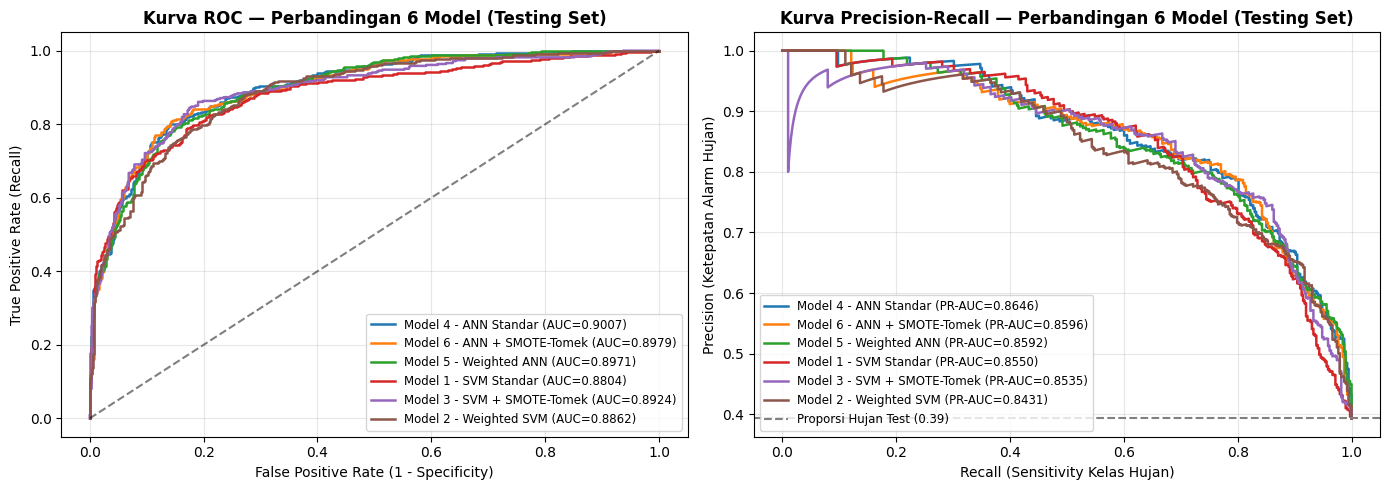

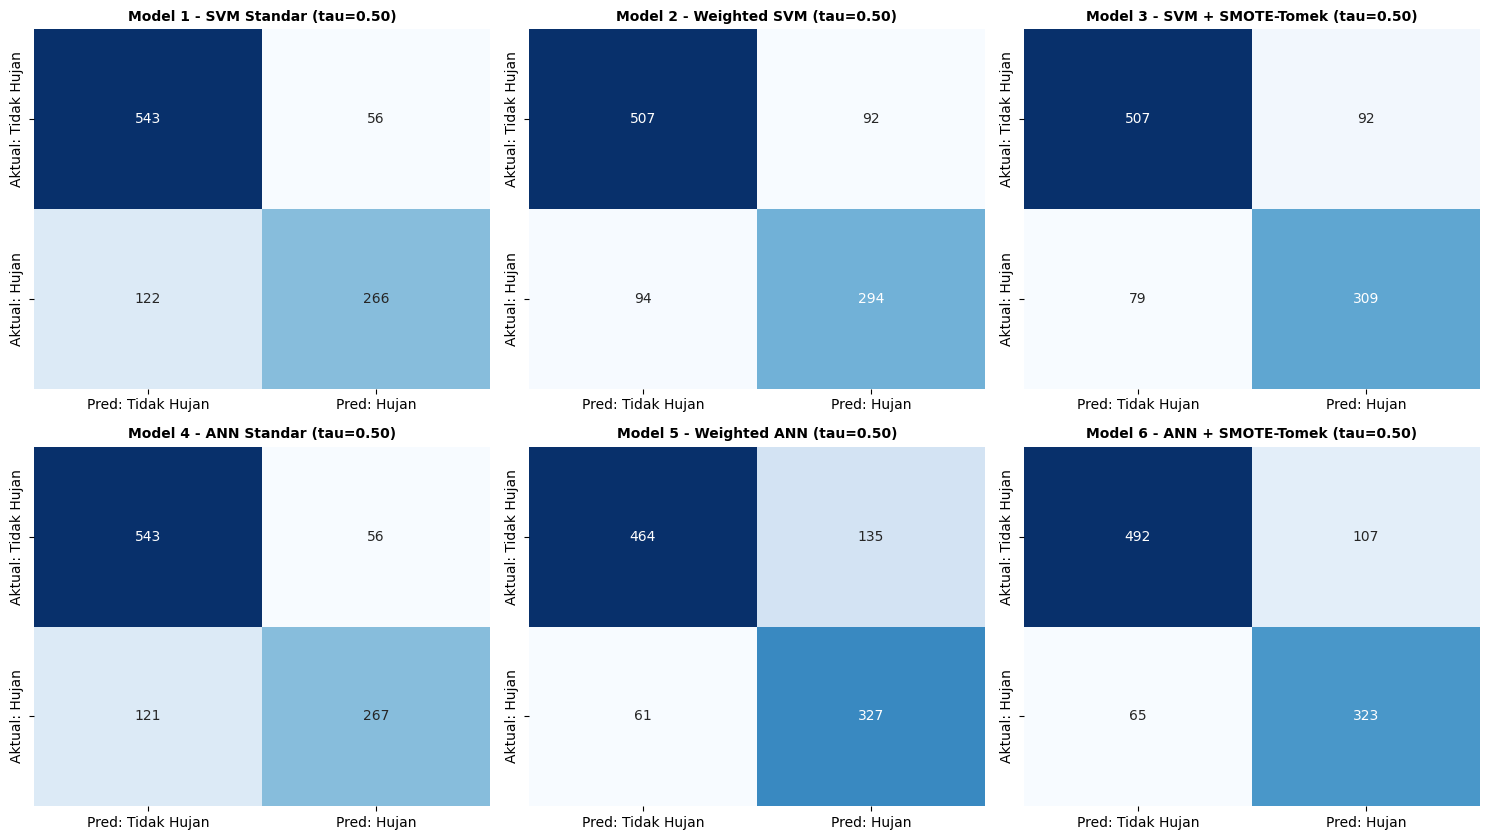

In [7]:
print(f"TAHAP 6: PERBANDINGAN PERFORMA SELURUH 6 MODEL PADA TESTING SET (n = {len(test_df)} JAM | tau = 0.50)")

def prediksi_probabilitas(model, X_data, tipe="svm"):
    if tipe == "svm":
        return model.predict_proba(X_data)[:, 1]
    else:
        model.eval()
        with torch.no_grad():
            t_x = torch.tensor(X_data, dtype=torch.float32, device=DEVICE)
            return torch.sigmoid(model(t_x)).cpu().numpy()

def hitung_metrik_lengkap(y_true, y_prob, threshold=0.50, sudden_mask=None):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    sudden_rec = float(y_pred[sudden_mask].mean()) if sudden_mask is not None and sudden_mask.sum() > 0 else np.nan
    return {
        "PR_AUC": average_precision_score(y_true, y_prob),
        "F1_Score_Hujan": f1_score(y_true, y_pred, zero_division=0),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "Precision_Hujan": precision_score(y_true, y_pred, zero_division=0),
        "Recall_Hujan": recall_score(y_true, y_pred, zero_division=0),
        "Sudden_Rain_Recall": sudden_rec,
        "Accuracy": accuracy_score(y_true, y_pred),
        "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
    }

# Penanda khusus kejadian hujan mendadak di Testing Set (saat jam sekarang kering, 1 jam lagi hujan)
sudden_mask_test = (test_df["rain_prev_1h"].values < 0.05) & (y_test == 1)

daftar_model = [
    ("Model 1 - SVM Standar", svm_base, "svm"),
    ("Model 2 - Weighted SVM", svm_weight, "svm"),
    ("Model 3 - SVM + SMOTE-Tomek", svm_smote, "svm"),
    ("Model 4 - ANN Standar", ann_base, "ann"),
    ("Model 5 - Weighted ANN", ann_weight, "ann"),
    ("Model 6 - ANN + SMOTE-Tomek", ann_smote, "ann"),
]

hasil_evaluasi = []
probabilitas_test_dict = {}

for nama_m, obj_m, tipe_m in daftar_model:
    y_prob_t = prediksi_probabilitas(obj_m, X_test_sc, tipe=tipe_m)
    probabilitas_test_dict[nama_m] = y_prob_t
    m_dict = hitung_metrik_lengkap(y_test, y_prob_t, threshold=0.50, sudden_mask=sudden_mask_test)
    m_dict["Model"] = nama_m
    hasil_evaluasi.append(m_dict)

df_hasil = pd.DataFrame(hasil_evaluasi)
kolom_urutan = [
    "Model", "PR_AUC", "F1_Score_Hujan", "Balanced_Accuracy",
    "ROC_AUC", "Precision_Hujan", "Recall_Hujan", "Sudden_Rain_Recall",
    "Accuracy", "TP", "FN", "FP", "TN"
]
df_hasil = df_hasil[kolom_urutan]

# Urutkan tabel perbandingan berdasarkan PR-AUC dan F1-Score kelas Hujan
df_ranking = df_hasil.sort_values(by=["PR_AUC", "F1_Score_Hujan"], ascending=False).reset_index(drop=True)
print(df_ranking.round(4).to_string(index=False))

# Visualisasi Perbandingan 6 Model (Kurva ROC, Kurva PR, & Confusion Matrix)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for nama_m in df_ranking["Model"]:
    y_p = probabilitas_test_dict[nama_m]
    fpr, tpr, _ = roc_curve(y_test, y_p)
    auc_val = roc_auc_score(y_test, y_p)
    axes[0].plot(fpr, tpr, linewidth=1.8, label=f"{nama_m} (AUC={auc_val:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("Kurva ROC — Perbandingan 6 Model (Testing Set)", fontweight="bold")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right", fontsize=8.5)
axes[0].grid(alpha=0.3)

baseline_prev = y_test.mean()
for nama_m in df_ranking["Model"]:
    y_p = probabilitas_test_dict[nama_m]
    prec, rec, _ = precision_recall_curve(y_test, y_p)
    ap_val = average_precision_score(y_test, y_p)
    axes[1].plot(rec, prec, linewidth=1.8, label=f"{nama_m} (PR-AUC={ap_val:.4f})")
axes[1].axhline(baseline_prev, color="gray", linestyle="--", label=f"Proporsi Hujan Test ({baseline_prev:.2f})")
axes[1].set_title("Kurva Precision-Recall — Perbandingan 6 Model (Testing Set)", fontweight="bold")
axes[1].set_xlabel("Recall (Sensitivity Kelas Hujan)")
axes[1].set_ylabel("Precision (Ketepatan Alarm Hujan)")
axes[1].legend(loc="lower left", fontsize=8.5)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("evaluasi_kurva_6_model.png", dpi=200)
plt.show()

urutan_cm = [
    "Model 1 - SVM Standar", "Model 2 - Weighted SVM", "Model 3 - SVM + SMOTE-Tomek",
    "Model 4 - ANN Standar", "Model 5 - Weighted ANN", "Model 6 - ANN + SMOTE-Tomek"
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, nama_m in zip(axes.ravel(), urutan_cm):
    y_pred_m = (probabilitas_test_dict[nama_m] >= 0.50).astype(int)
    cm = confusion_matrix(y_test, y_pred_m)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Pred: Tidak Hujan", "Pred: Hujan"],
        yticklabels=["Aktual: Tidak Hujan", "Aktual: Hujan"]
    )
    ax.set_title(f"{nama_m} (tau=0.50)", fontweight="bold", fontsize=10)
plt.tight_layout()
plt.savefig("confusion_matrix_6_model.png", dpi=200)
plt.show()

TAHAP 7: ANALISIS MENDALAM MODEL TERPILIH (TANPA KALIBRASI THRESHOLD)
1. Model Terpilih            : Model 6 - ANN + SMOTE-Tomek
2. Ambang Batas Keputusan    : tau = 0.50 (50% - Standar)
3. Performa Model Terpilih   : PR-AUC=0.8596 | F1-Score=0.7897 | Balanced Acc=0.8269 | Recall=0.8325 | Precision=0.7512 | ROC-AUC=0.8979
4. Confusion Matrix Test Set : TP=323 | FN=65 | FP=107 | TN=492
5. Deteksi Hujan Mendadak    : Terdeteksi 46.81% dari 94 kejadian hujan mendadak di Testing Set
6. Pembagian Zona Keputusan  : Zona Hijau (Aman) < 50% | Zona Kuning (Waspada) 50% - 69% | Zona Merah (Siaga) >= 70%

7. Top 8 Variabel Paling Berpengaruh pada Keputusan Model Terpilih:
                Fitur  Penurunan_PR_AUC
  shortwave_radiation            0.1102
       is_raining_now            0.0954
      cloud_cover_low            0.0558
         rain_prev_1h            0.0390
          rain_sum_3h            0.0198
boundary_layer_height            0.0194
    cloud_low_diff_1h            0.0160
       win

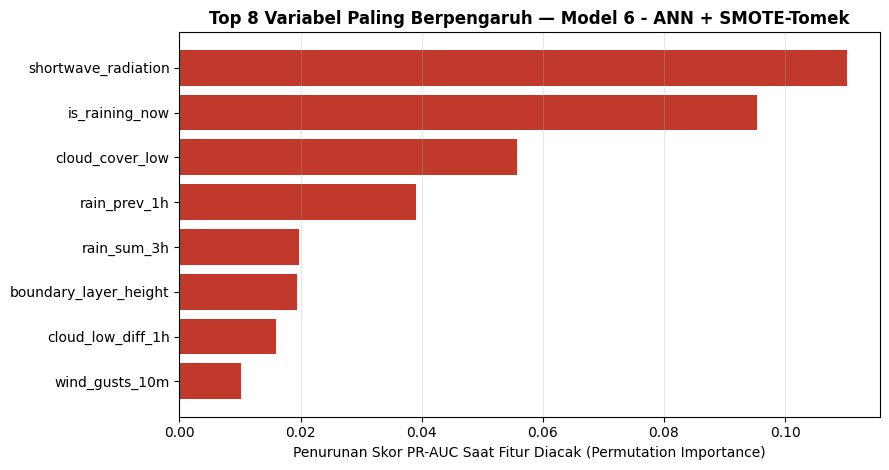

In [8]:
MODEL_TERPILIH = "Model 6 - ANN + SMOTE-Tomek"
THRESHOLD_STANDAR = 0.50

dict_model = dict((n, (m, t)) for n, m, t in daftar_model)
assert MODEL_TERPILIH in dict_model, f"Nama model '{MODEL_TERPILIH}' tidak ditemukan!"

obj_terpilih, tipe_terpilih = dict_model[MODEL_TERPILIH]

# 1. Hitung performa detail Model Terpilih pada Testing Set (tau = 0.50)
metrik_model_terpilih = hitung_metrik_lengkap(
    y_test,
    probabilitas_test_dict[MODEL_TERPILIH],
    threshold=THRESHOLD_STANDAR,
    sudden_mask=sudden_mask_test
)

# 2. Hitung Permutation Feature Importance untuk mencari Top 8 Variabel Paling Berpengaruh
base_pr_auc = average_precision_score(y_test, probabilitas_test_dict[MODEL_TERPILIH])
imp_records = []
rng = np.random.default_rng(SEED)

for idx_f, nama_f in enumerate(fitur_prediktor):
    drops = []
    for _ in range(5):
        X_perm = X_test_sc.copy()
        X_perm[:, idx_f] = rng.permutation(X_perm[:, idx_f])
        p_perm = prediksi_probabilitas(obj_terpilih, X_perm, tipe=tipe_terpilih)
        drops.append(base_pr_auc - average_precision_score(y_test, p_perm))
    imp_records.append({"Fitur": nama_f, "Penurunan_PR_AUC": np.mean(drops)})

df_importance = pd.DataFrame(imp_records).sort_values("Penurunan_PR_AUC", ascending=False).reset_index(drop=True)

print("TAHAP 7: ANALISIS MENDALAM MODEL TERPILIH (TANPA KALIBRASI THRESHOLD)")
print(f"1. Model Terpilih            : {MODEL_TERPILIH}")
print(f"2. Ambang Batas Keputusan    : tau = {THRESHOLD_STANDAR:.2f} (50% - Standar)")
print(f"3. Performa Model Terpilih   : PR-AUC={metrik_model_terpilih['PR_AUC']:.4f} | "
      f"F1-Score={metrik_model_terpilih['F1_Score_Hujan']:.4f} | "
      f"Balanced Acc={metrik_model_terpilih['Balanced_Accuracy']:.4f} | "
      f"Recall={metrik_model_terpilih['Recall_Hujan']:.4f} | "
      f"Precision={metrik_model_terpilih['Precision_Hujan']:.4f} | "
      f"ROC-AUC={metrik_model_terpilih['ROC_AUC']:.4f}")
print(f"4. Confusion Matrix Test Set : TP={metrik_model_terpilih['TP']} | FN={metrik_model_terpilih['FN']} | "
      f"FP={metrik_model_terpilih['FP']} | TN={metrik_model_terpilih['TN']}")
print(f"5. Deteksi Hujan Mendadak    : Terdeteksi {metrik_model_terpilih['Sudden_Rain_Recall']*100:.2f}% "
      f"dari {sudden_mask_test.sum()} kejadian hujan mendadak di Testing Set")
print(f"6. Pembagian Zona Keputusan  : Zona Hijau (Aman) < 50% | "
      f"Zona Kuning (Waspada) 50% - 69% | Zona Merah (Siaga) >= 70%")
print("\n7. Top 8 Variabel Paling Berpengaruh pada Keputusan Model Terpilih:")
print(df_importance.head(8).round(4).to_string(index=False))

# Visualisasi Top 8 Variabel Paling Berpengaruh
top8 = df_importance.head(8).iloc[::-1]
plt.figure(figsize=(9, 4.8))
plt.barh(top8["Fitur"], top8["Penurunan_PR_AUC"], color="#C0392B")
plt.title(f"Top 8 Variabel Paling Berpengaruh — {MODEL_TERPILIH}", fontweight="bold")
plt.xlabel("Penurunan Skor PR-AUC Saat Fitur Diacak (Permutation Importance)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("top8_fitur_model_terpilih.png", dpi=200)
plt.show()

In [9]:
df_ranking.to_csv("hasil_evaluasi_6_model.csv", index=False)
df_importance.to_csv("feature_importance_model_terpilih.csv", index=False)

ann_artifacts = {}
for nama_m, obj_m, tipe_m in daftar_model:
    if tipe_m == "ann":
        ann_artifacts[nama_m] = {
            "state_dict": {k: v.cpu() for k, v in obj_m.state_dict().items()},
            "hidden_layers": info_semua_model[nama_m]["hidden_layers"]
        }

artefak_streamlit = {
    "scaler": scaler,
    "fitur_prediktor": fitur_prediktor,
    "nama_model_terpilih": MODEL_TERPILIH,
    "threshold_standar": THRESHOLD_STANDAR,
    "svm_models": {
        "Model 1 - SVM Standar": svm_base,
        "Model 2 - Weighted SVM": svm_weight,
        "Model 3 - SVM + SMOTE-Tomek": svm_smote,
    },
    "ann_models": ann_artifacts,
    "info_hiperparameter": info_semua_model,
    "metrik_model_terpilih": metrik_model_terpilih,
    "top8_fitur": df_importance.head(8).to_dict(orient="records"),
    "eda_summary": {
        "total_observasi": int(baris_akhir),
        "jumlah_tidak_hujan": int(vc[0]),
        "jumlah_hujan": int(vc[1]),
        "imbalance_ratio": round(float(ir), 2),
        "persen_hujan_mendadak": round(float(persen_mendadak), 2)
    }
}

joblib.dump(artefak_streamlit, "artefak_hujan_pekanbaru.joblib")
print(f"[SUKSES] Model terpilih '{MODEL_TERPILIH}' (tau = {THRESHOLD_STANDAR}) & seluruh file output berhasil disimpan!")

[SUKSES] Model terpilih 'Model 6 - ANN + SMOTE-Tomek' (tau = 0.5) & seluruh file output berhasil disimpan!
